# Sales pipeline analysis

The questions a sales director asks me every quarter, answered on a synthetic B2B pipeline (4,200 deals, January 2024 to the snapshot of 30 September 2026):

1. Where do deals die, and which channels and segments convert?
2. How long does it take to close, and are we growing?
3. How concentrated is the partner channel?
4. What is the open pipeline really worth, and what will we book in Q4?

All the logic lives in the SQL files in `sql/` and the modules in `src/`. This notebook runs them and comments on the results. The same numbers are produced by `python src/run_analysis.py`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import analysis, charts, forecast, win_model

FIG = ROOT / "reports" / "figures"
pd.set_option("display.float_format", lambda x: f"{x:,.3f}" if abs(x) < 10 else f"{x:,.0f}")

r = analysis.run_all()
deals = r["deals"]
print(f"Deals: {len(deals):,}   closed: {int(deals.is_closed.sum()):,}   "
      f"won: {int(deals.is_won.sum()):,}   open at snapshot: {int((~deals.is_closed).sum())}")

Deals: 4,200   closed: 3,995   won: 1,254   open at snapshot: 205


## 1. Where deals die

Only closed deals are counted in the funnel. Open deals have not had the chance to pass or fail yet, and leaving them in would make every stage look leakier than it is.

,stage,deals_reached,conversion_from_previous,conversion_from_start,deals_lost_here,share_of_all_losses
0,Discovery,3995,NaN,1.000,900,0.328
1,Qualified,3095,0.775,0.775,600,0.219
2,Proposal,2495,0.806,0.625,488,0.178
3,Negotiation,2007,0.804,0.502,753,0.275
4,Closed Won,1254,0.625,0.314,0,0.000


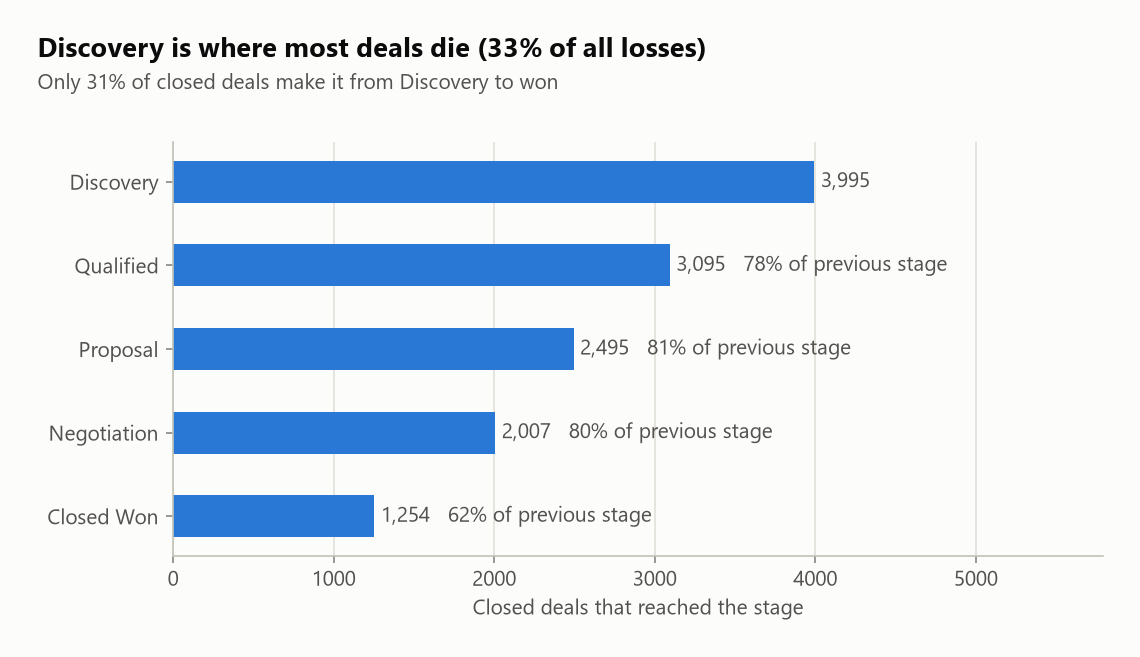

In [2]:
charts.funnel(r["funnel"], FIG / "01_funnel.png")
display(r["funnel"])
Image(FIG / "01_funnel.png")

Each stage loses roughly one deal in five, so the absolute losses are biggest at the top: a third of all lost deals never get past Discovery, and almost half of those are "no response" (section 5). The other spot worth attention is Negotiation, with 27% of losses: these deals have already consumed most of the sales effort.

## 2. Who converts

Win rate is won over closed. Next to each rate there is a 95% Wilson interval, computed in SQL, because a difference of five points means something on 2,000 deals and nothing on 200.

,dimension,value,closed_deals,won_deals,win_rate,ci_low,ci_high
4,channel,Referral,584,308,0.527,0.487,0.568
5,channel,Partner,1503,501,0.333,0.310,0.358
6,channel,Direct,1908,445,0.233,0.215,0.253
7,deal_type,Upsell,628,299,0.476,0.437,0.515
8,deal_type,New business,3367,955,0.284,0.269,0.299
12,size_segment,Medium,1114,365,0.328,0.301,0.356
13,size_segment,Small,1875,614,0.327,0.307,0.349
14,size_segment,Micro,805,230,0.286,0.256,0.318
15,size_segment,Large,201,45,0.224,0.172,0.286


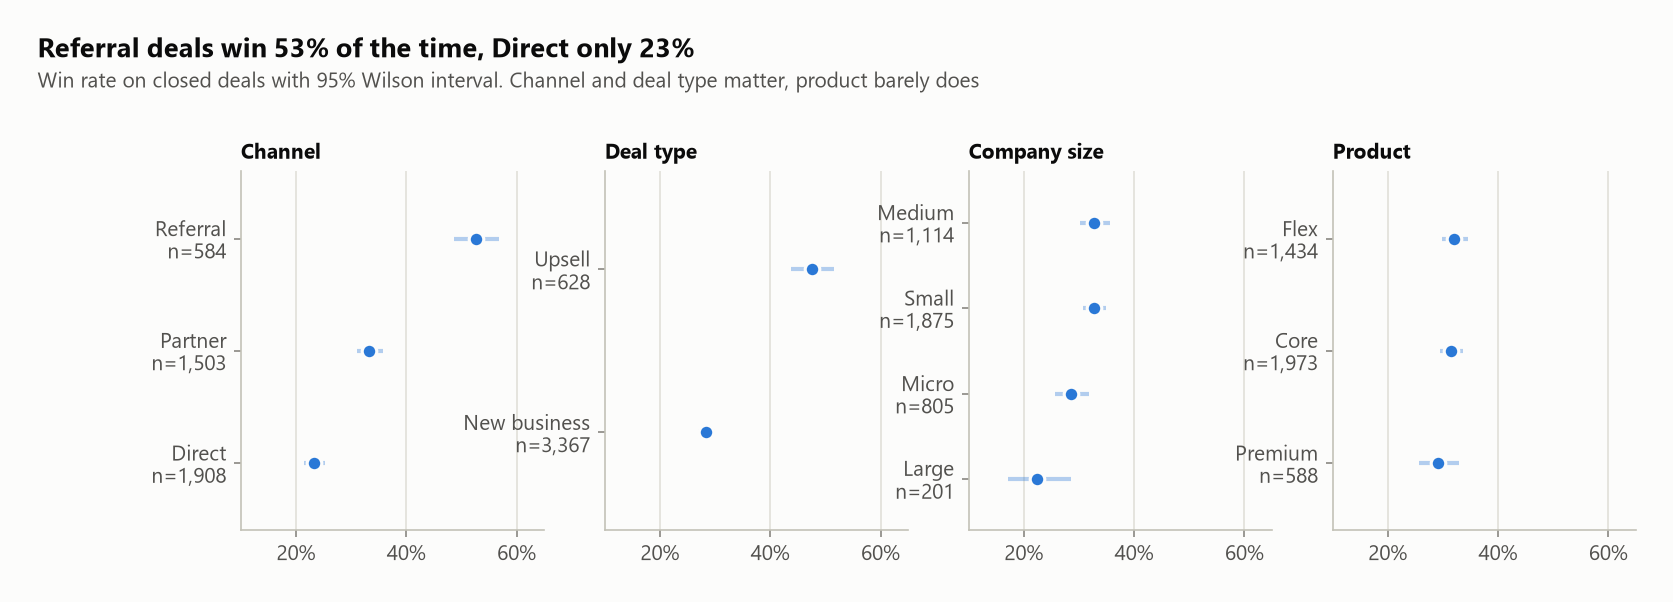

In [3]:
charts.win_rates(r["win_rates"], FIG / "02_win_rates.png")
display(r["win_rates"].query("dimension in ['channel', 'deal_type', 'size_segment']"))
Image(FIG / "02_win_rates.png")

Referral deals win 53% of the time, partner deals 33%, direct deals 23%, and the intervals are far apart. Upsell to existing customers converts at 48% against 28% for new business. Large companies are the hardest segment (22%, on only 201 closed deals, so the interval is wide). Product makes little difference: Premium is a bit lower, but its interval overlaps the others.

## 3. How long it takes

Cycle length comes from the stage history: days from the first stage to the closing row. Medians and percentiles rather than averages, because a few deals that sit for months drag the mean around.

,size_segment,won_deals,won_p50,won_p75,won_p90,won_p50_new_business,won_p50_upsell,closed_deals,closed_p50
0,Micro,230,27,38,52,30,20,805,15
1,Small,614,48,69,89,56,31,1875,30
2,Medium,365,75,108,140,83,48,1114,48
3,Large,45,119,162,213,121,36,201,64


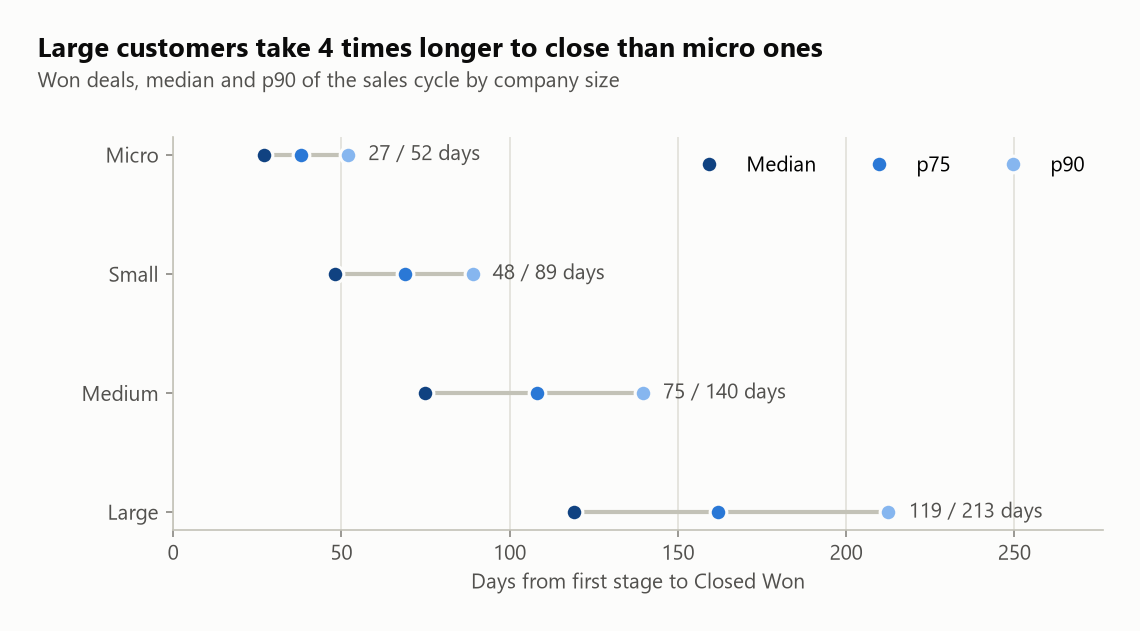

In [4]:
charts.sales_cycle(r["sales_cycle"], FIG / "03_sales_cycle.png")
display(r["sales_cycle"])
Image(FIG / "03_sales_cycle.png")

A won micro deal closes in a median of 27 days, a large one in 119, and one large deal in ten takes more than 200 days. That matters for the forecast: a large deal created in October is unlikely to land in the same quarter. Upsells close faster than new business in every segment.

## 4. Growth and seasonality

2026 stops at the snapshot date, so years are compared January to September only.

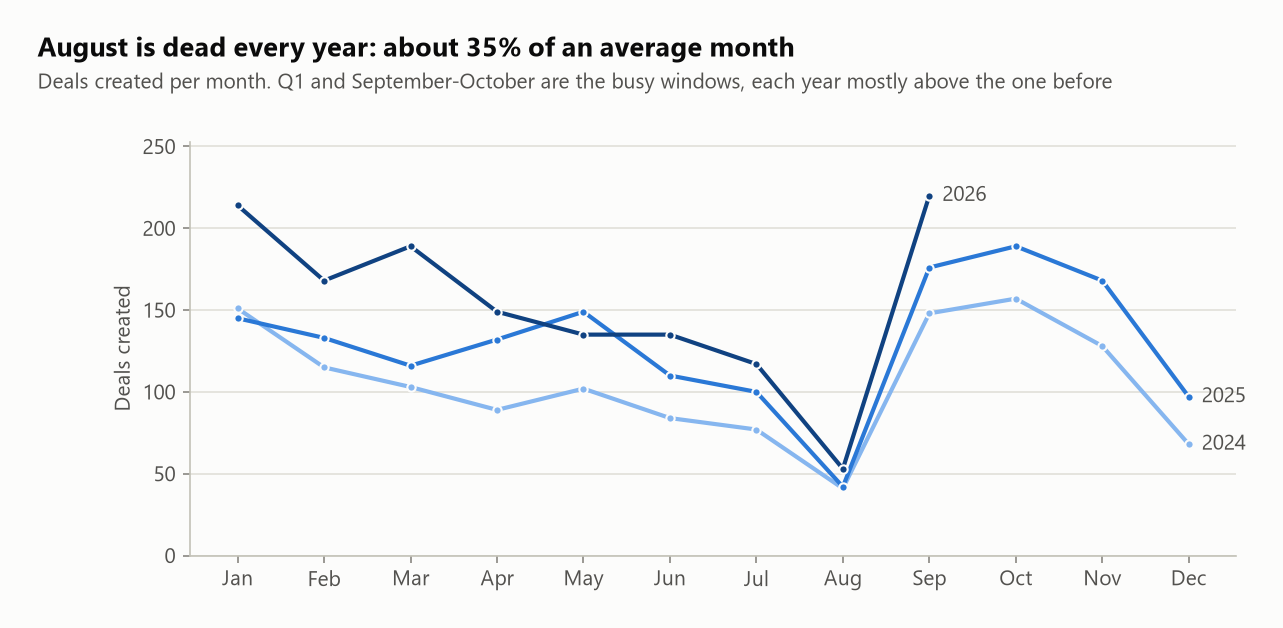

,year,period,deals_created,deals_created_yoy,pipeline_created,deals_won,bookings,bookings_yoy,partner_share
0,2024,Jan-Sep,910,NaN,"5,275,300",214,"862,760",NaN,0.310
1,2025,Jan-Sep,1103,0.212,"6,176,310",313,"1,432,400",0.660,0.380
2,2026,Jan-Sep,1380,0.251,"6,910,270",482,"2,422,720",0.691,0.432


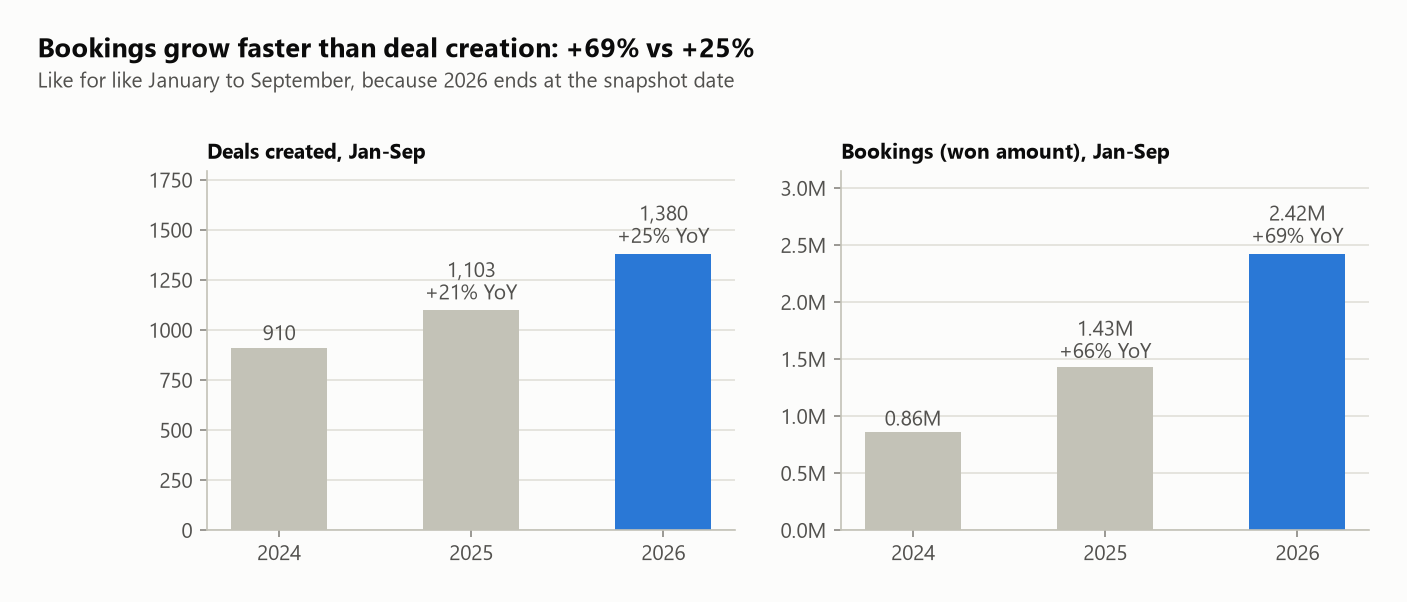

In [5]:
charts.seasonality(r["seasonality"], FIG / "05_seasonality.png")
charts.growth_ytd(r["yoy_ytd"], FIG / "06_growth_ytd.png")
display(Image(FIG / "05_seasonality.png"))
display(r["yoy_ytd"])
Image(FIG / "06_growth_ytd.png")

The yearly shape is stable: busy January, a second peak in September and October, and an August at about a third of an average month. Anyone setting monthly targets flat across the year will see a "miss" every August that is just the calendar.

Deal creation grows about 20 to 25% a year, but bookings grow much faster (+69% in 2026 vs 2025). Two cautions before quoting that number. First, the 2025 vs 2024 comparison is inflated: the dataset starts in January 2024 with an empty pipeline, so the first months of 2024 have almost nothing to close. Second, the 2026 jump is real but has identifiable drivers: upsell grew from 13% to 27% of new deals as the customer base grew, and partner deals from 38% to 43%. Both convert better than the average, so the same number of new deals now produces more wins.

## 5. Channel mix, partners and lost reasons

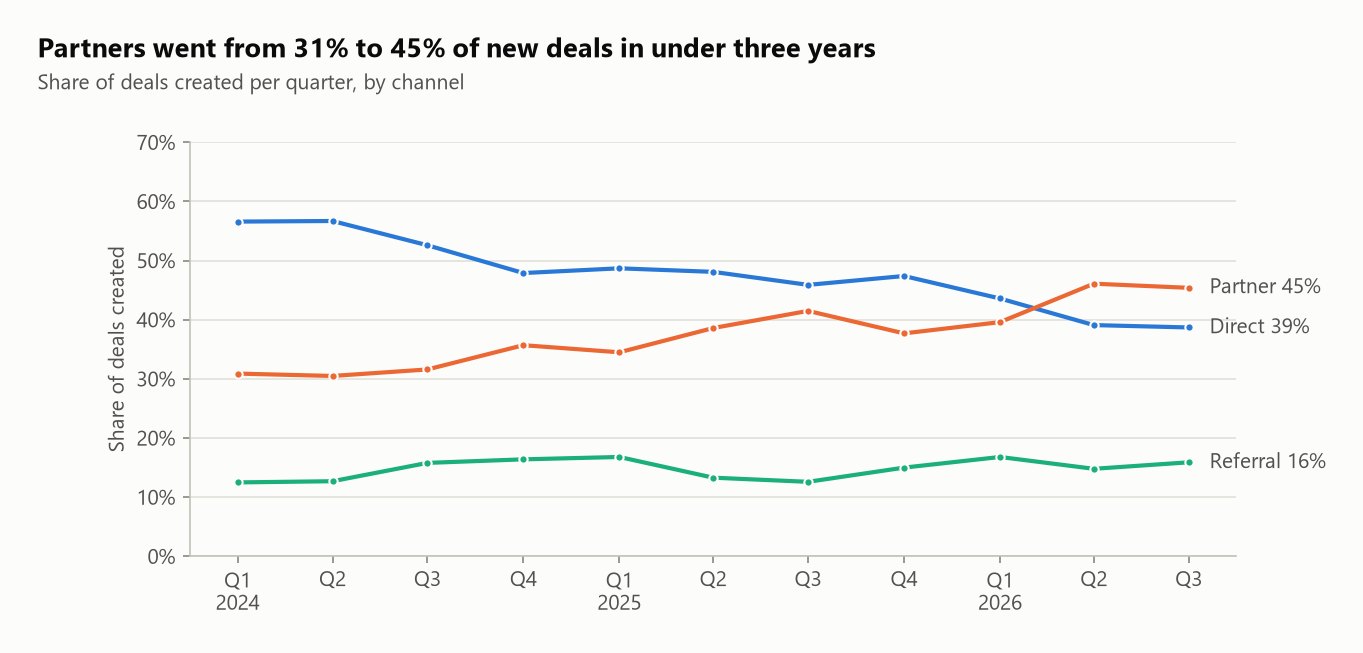

,rank,partner_name,partner_type,deals,won_deals,bookings,share,cumulative_share,in_top_80pct
0,1,Rete Moccia,Payroll consultant,408,134,"669,690",0.279,0.279,True
1,2,Studio Contrafatto,Accounting firm,198,57,"361,100",0.150,0.429,True
2,3,Studio Peruzzi,Trade association,143,54,"227,830",0.095,0.524,True
3,4,Consulenti Bonolis,Payroll consultant,91,25,"160,350",0.067,0.591,True
4,5,Studio Ossola,Broker,82,26,"143,550",0.060,0.650,True
5,6,Gruppo Bellucci,Broker,91,29,"133,910",0.056,0.706,True
6,7,Studio Caccianemico,Trade association,77,24,"113,930",0.047,0.753,True
7,8,Studio Bevilacqua,Payroll consultant,43,12,"84,460",0.035,0.789,True
8,9,Gruppo Brichese,Payroll consultant,38,17,"82,060",0.034,0.823,True
9,10,Consulenti Valentino,Accounting firm,67,22,"69,360",0.029,0.852,False


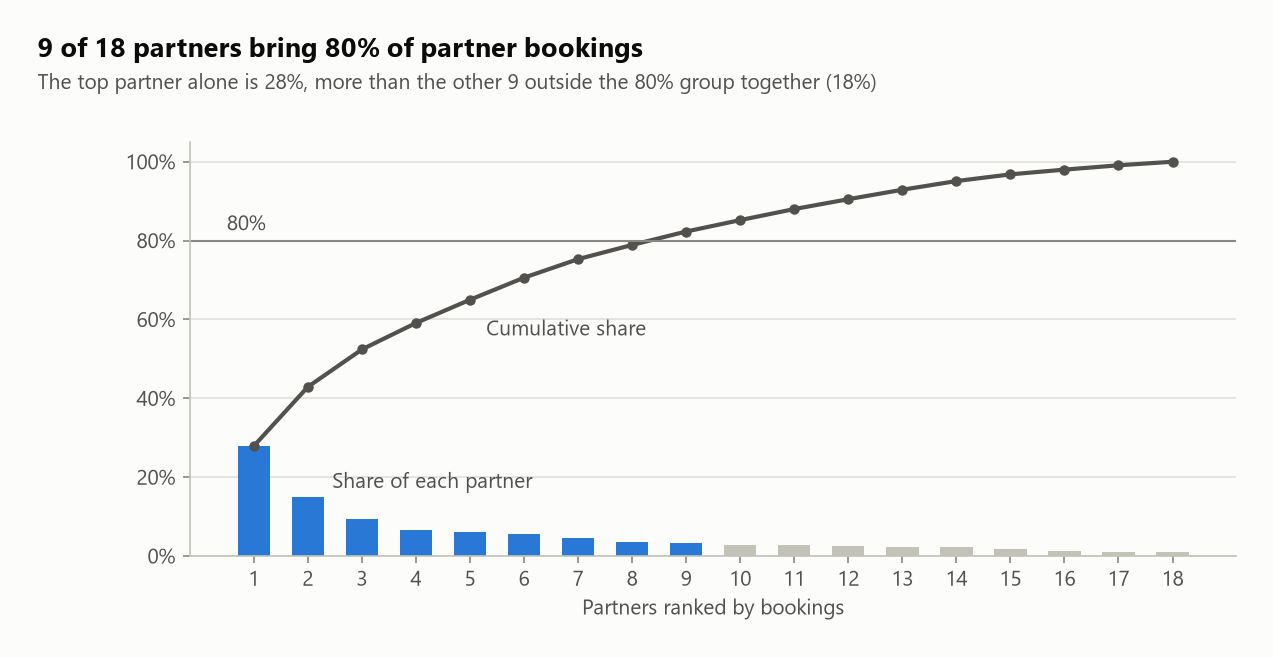

In [6]:
charts.channel_mix(r["channel_mix"], FIG / "07_channel_mix.png")
charts.partner_pareto(r["partner_pareto"], FIG / "04_partner_pareto.png")
display(Image(FIG / "07_channel_mix.png"))
display(r["partner_pareto"].head(10))
Image(FIG / "04_partner_pareto.png")

Partners went from 31% to 45% of new deals and overtook direct sales in Q2 2026. Inside the channel, 9 partners out of 18 bring 80% of partner bookings and the top one alone brings 28%. With the channel now the largest source of deals, that single relationship is a risk worth managing explicitly.

,stage_lost_at,lost_deals,no_response,not_a_fit,timing,no_budget,price,competitor,lost_amount
0,Discovery,900,0.476,0.302,0.222,0.000,0.000,0.000,"5,343,180"
1,Qualified,600,0.233,0.000,0.323,0.443,0.000,0.000,"2,828,220"
2,Proposal,488,0.000,0.000,0.000,0.281,0.424,0.295,"2,908,430"
3,Negotiation,753,0.000,0.000,0.157,0.000,0.429,0.414,"4,245,890"


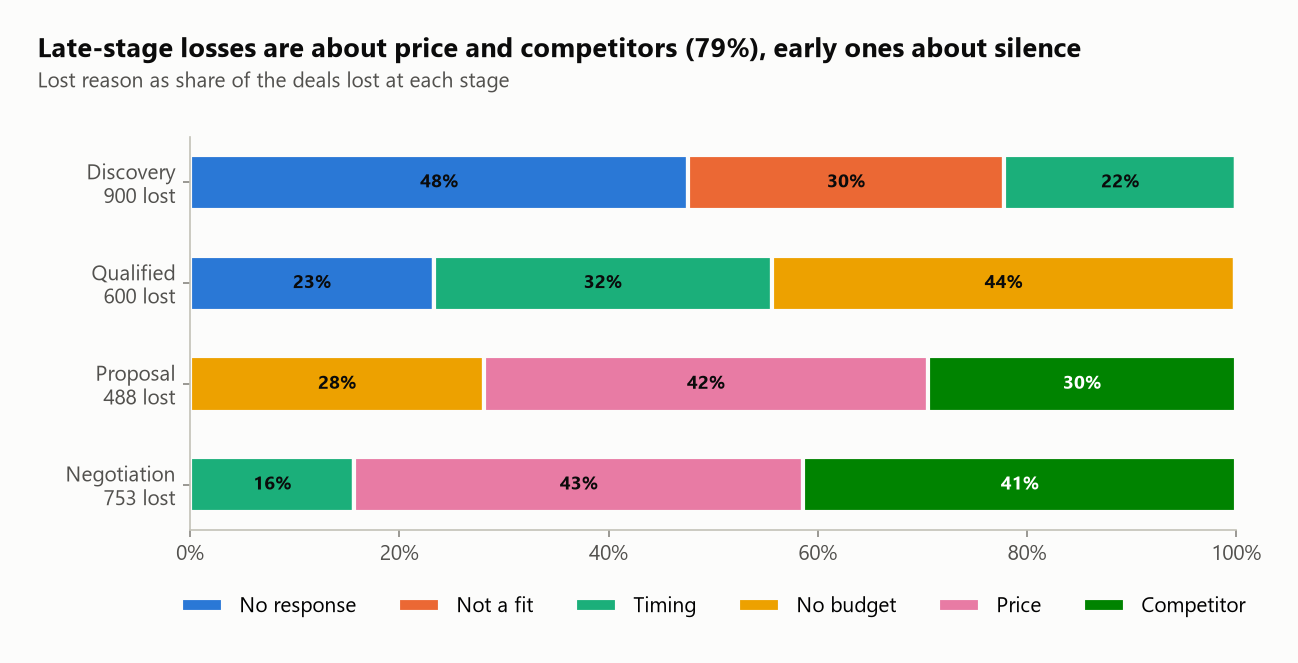

In [7]:
charts.lost_reasons(r["lost_reasons"], FIG / "10_lost_reasons.png")
display(r["lost_reasons"])
Image(FIG / "10_lost_reasons.png")

Losses change nature along the funnel. Early on it is silence and bad fit (no response is 48% of Discovery losses), which is a qualification problem. From Proposal onwards it is price and competitors (79% of late losses), which is a pricing and positioning problem. Two different conversations, with two different teams.

## 6. Cohorts: are recent deals worse?

Reading win rate by month of creation is the quickest way to check whether deal quality is changing. The catch is maturity: fast losses close first, so a young cohort always looks bad.

,cohort_month,deals_created,closed,won,open_share,win_rate_closed,win_rate_all_created,bookings
27,2026-04-01,149,146,60,0.020,0.411,0.403,"226,380"
28,2026-05-01,135,135,44,0.000,0.326,0.326,"109,760"
29,2026-06-01,135,127,44,0.059,0.346,0.326,"124,120"
30,2026-07-01,117,105,42,0.103,0.400,0.359,"163,150"
31,2026-08-01,53,29,6,0.453,0.207,0.113,"7,200"
32,2026-09-01,220,63,9,0.714,0.143,0.041,"11,660"


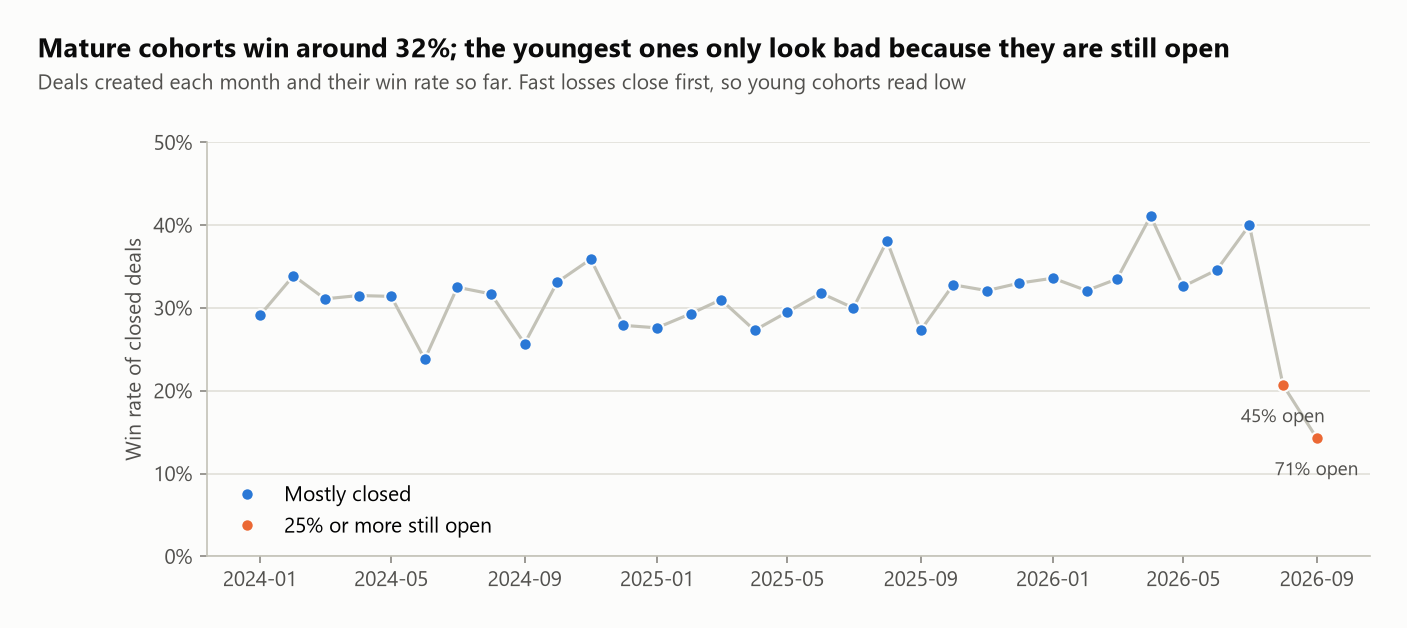

In [8]:
charts.cohorts(r["cohorts"], FIG / "08_cohorts.png")
display(r["cohorts"].tail(6))
Image(FIG / "08_cohorts.png")

Cohorts that are mostly closed sit around 32%, with a slight upward drift in 2026 that matches the mix shift above. August and September 2026 read 21% and 14%, but 45% and 71% of their deals are still open. Nothing has gone wrong with them yet; this is the chart I show when someone panics about last month's win rate.

## 7. The open pipeline at the snapshot

Each open deal is weighted by the historical rate at which deals that reached its stage were eventually won. A deal is flagged as stuck when it has spent longer in its current stage than 90% of past deals of the same size in that stage.

,stage,open_deals,pipeline_amount,p_win_from_stage,weighted_amount,stuck_deals,stuck_amount,median_days_in_stage
0,Discovery,85,"586,070",0.314,"183,975",3,"18,040",6.000
1,Qualified,48,"325,210",0.405,"131,761",3,"48,810",5.000
2,Proposal,38,"199,280",0.503,"100,158",2,"8,550",6.500
3,Negotiation,34,"330,130",0.625,"206,273",6,"62,660",9.000


,deal_id,stage,size_segment,amount,days_in_stage,p90_days
73,3699,Qualified,Large,"39,840",89,74
2,3432,Negotiation,Large,"28,360",84,70
5,3850,Negotiation,Large,"25,650",74,70
137,3859,Discovery,Medium,"9,060",79,39
139,3949,Discovery,Medium,"7,780",44,39
41,3936,Proposal,Medium,"7,350",40,38
89,3827,Qualified,Medium,"4,880",71,39
93,3947,Qualified,Small,"4,090",32,25


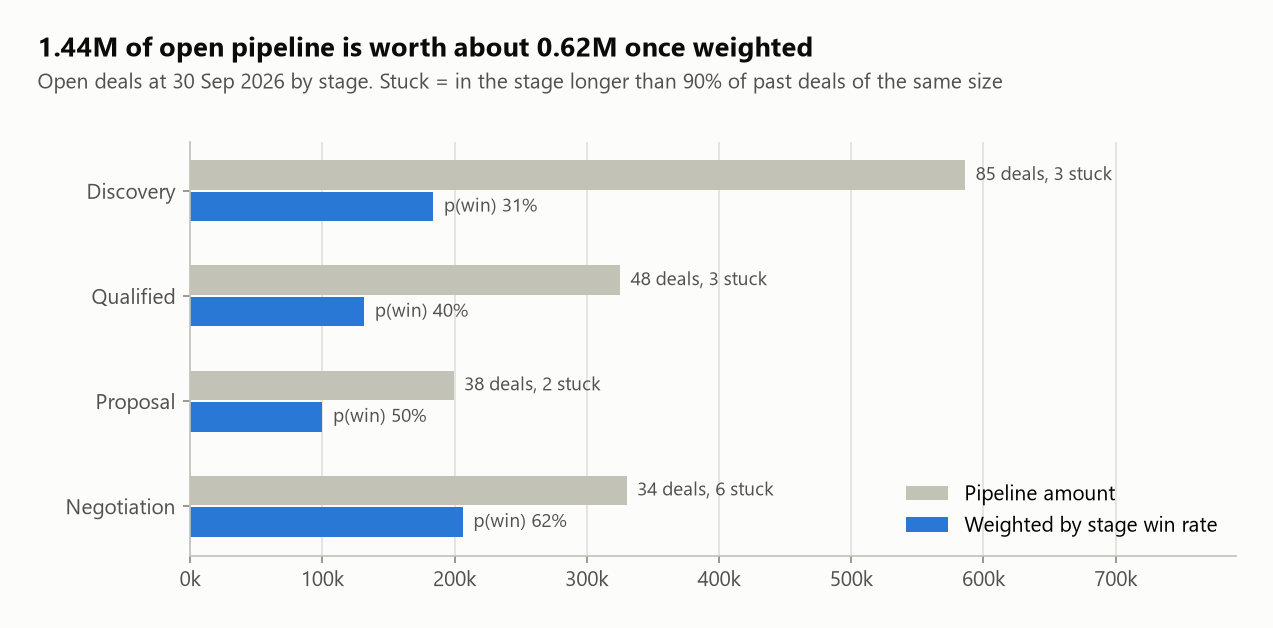

In [9]:
charts.open_pipeline(r["pipeline_by_stage"], FIG / "09_open_pipeline.png")
display(r["pipeline_by_stage"])
display(r["open_pipeline"].query("is_stuck").sort_values("amount", ascending=False)
        [["deal_id", "stage", "size_segment", "amount", "days_in_stage", "p90_days"]].head(8))
Image(FIG / "09_open_pipeline.png")

1.44M of open pipeline is worth about 0.62M once weighted, and Discovery holds 41% of the amount but only 30% of the weighted value. Fourteen deals (138k) are stuck. My first version used one p90 per stage and flagged almost only Medium and Large deals, which was just telling me that big deals are slow; comparing each deal with its own size class gives a list a sales manager can actually call through.

## 8. Win probability model

The question: given what we know when a deal is created, how likely is it to be won? Two rules:

* only features known at creation (channel, deal type, product, company size, sector, region, partner type, amount, employees). Close date, stage, lost reason and cycle length are out, because they are only known once the deal has moved;
* a time-based split. The model is trained on deals that had already closed before 1 October 2025 and tested on deals created after that date, as if I had built it on that day.

Train: 2,202 deals closed before 2025-10-01   Test: 1,629 deals created after it


,model,roc_auc,brier,log_loss
0,Base rate only,0.500,0.224,0.640
1,Logistic regression,0.652,0.206,0.601
2,Gradient boosting,0.631,0.211,0.615


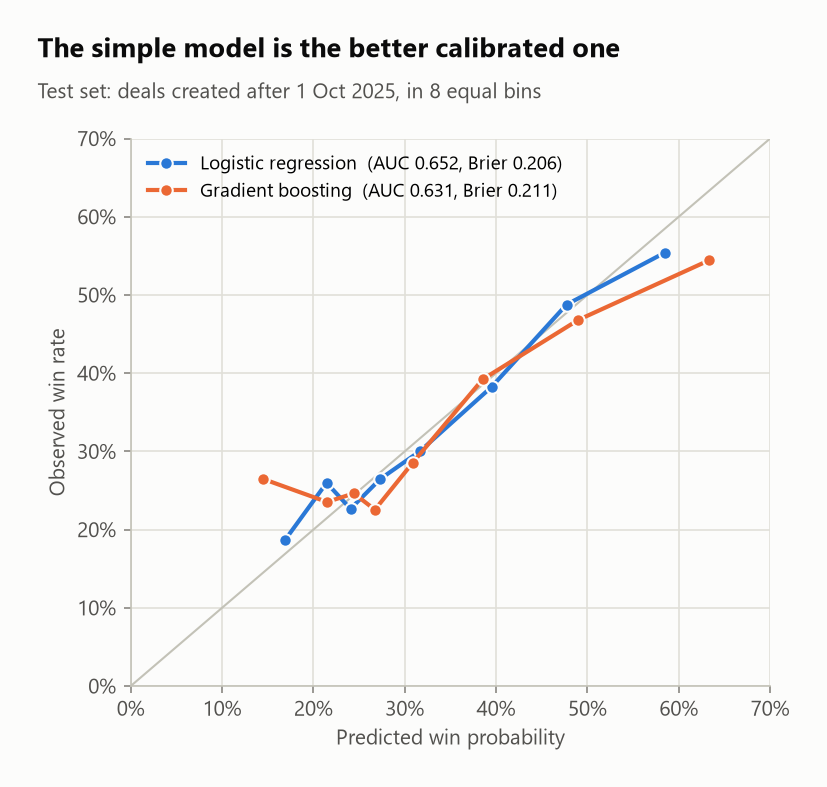

In [10]:
model = win_model.run(deals, r["open_pipeline"])
print(f"Train: {model.train_rows:,} deals closed before {win_model.CUTOFF}   "
      f"Test: {model.test_rows:,} deals created after it")
display(model.metrics)
charts.model_calibration(model.calibration, model.metrics, FIG / "11_model_calibration.png")
Image(FIG / "11_model_calibration.png")

Logistic regression reaches a test ROC AUC of 0.65 and a Brier score of 0.206, against 0.224 for a model that only knows the average win rate. Gradient boosting does slightly worse on both and is less calibrated at the edges. With a handful of categorical drivers and no strong interactions there is nothing for the extra flexibility to find, so the simple model stays.

An AUC of 0.65 is modest, and that is the honest result: most of what decides a deal happens after it is created. The model is useful for ranking and for an early read on a new deal, not for replacing the stage-based view.

,feature,coefficient,odds_ratio
2,channel_Referral,0.650,1.916
4,deal_type_Upsell,0.399,1.491
11,size_segment_Small,0.233,1.263
15,sector_Healthcare,0.169,1.184
19,sector_Manufacturing,0.162,1.176


,feature,coefficient,odds_ratio
30,partner_type_Trade association,-0.240,0.787
21,sector_Retail,-0.270,0.764
3,deal_type_New business,-0.545,0.580
8,size_segment_Large,-0.588,0.556
0,channel_Direct,-0.611,0.543


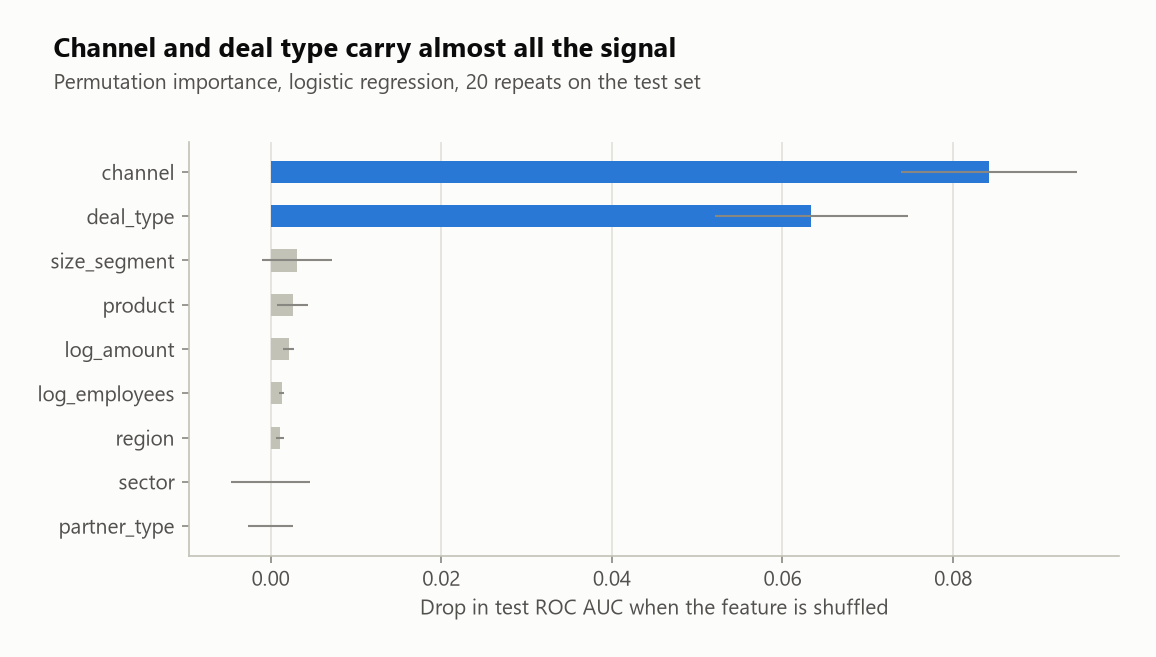

In [11]:
charts.model_importance(model.importance, FIG / "12_model_importance.png")
display(model.coefficients.head(5))
display(model.coefficients.tail(5))
Image(FIG / "12_model_importance.png")

Shuffling channel costs 0.084 of AUC and shuffling deal type 0.063; everything else is close to zero. The coefficients say the same thing in business terms: all else equal, a referral has about 3.5 times the odds of winning of a direct deal, an upsell about 2.6 times the odds of new business, and a large company less than half the odds of a small one.

Refitted on every closed deal, the model scores the open pipeline (`reports/tables/open_deals_scored.csv`). The top of that list is all referral upsells, which is where I would point the team first.

In [12]:
display(model.open_scored.head(8))

,deal_id,deal_name,channel,deal_type,size_segment,stage,amount,p_win_model,p_win_from_stage,weighted_amount,days_in_stage,is_stuck
0,3997,PONTI CONSTRUCTION | CORE | 2026,Referral,Upsell,Medium,Negotiation,"3,030",0.756,0.625,"1,893",4,False
1,4182,GIANNONE FINANCE | CORE | 2026,Referral,Upsell,Small,Discovery,"1,200",0.753,0.314,377,1,False
2,4198,VERGASSOLA HEALTHCARE | FLEX | 2026,Referral,Upsell,Small,Discovery,"1,200",0.728,0.314,377,0,False
3,4099,PALMISANO RETAIL | CORE | 2026,Referral,Upsell,Small,Negotiation,"1,200",0.725,0.625,750,2,False
4,4155,CAPONE FOOD | CORE | 2026,Referral,Upsell,Small,Qualified,"1,200",0.717,0.405,486,4,False
5,4190,GALEATI MANUFACTURING | CORE | 2026,Referral,Upsell,Small,Discovery,"1,200",0.715,0.314,377,1,False
6,4160,MERCADANTE HOSPITALITY | CORE | 2026,Referral,Upsell,Small,Discovery,"1,200",0.684,0.314,377,4,False
7,3966,BLASI LOGISTICS | CORE | 2026,Referral,Upsell,Micro,Negotiation,"1,200",0.671,0.625,750,15,False


## 9. Q4 2026 bookings forecast

Bookings in a quarter come from deals already open at the start of it, and from deals created and won inside it. The first part is the open pipeline weighted by the historical rate at which a deal open in that stage at a quarter end was won within the next quarter. The second is a seasonal naive run rate: the same quarter last year, scaled by the latest year over year growth in deal creation.

The method is replayed at every past quarter end using only what was known on that date. The range is the point forecast stretched by the smallest and largest error of that backtest.

,quarter,open_deals,from_open_pipeline,run_rate_new_deals,forecast,actual,error_pct
0,2025-Q2,180,"455,783","109,252","565,035","535,850",-0.052
1,2025-Q3,158,"403,169","96,115","499,284","388,720",-0.221
2,2025-Q4,164,"374,944","252,655","627,599","694,240",0.106
3,2026-Q1,175,"514,397","257,108","771,505","838,210",0.086
4,2026-Q2,235,"635,440","153,228","788,668","891,970",0.131
5,2026-Q3,185,"407,110","76,599","483,709","692,540",0.432


2026-Q4: 798,149  (range 621,403 to 1,142,733)   backtest mean absolute error 17.1%


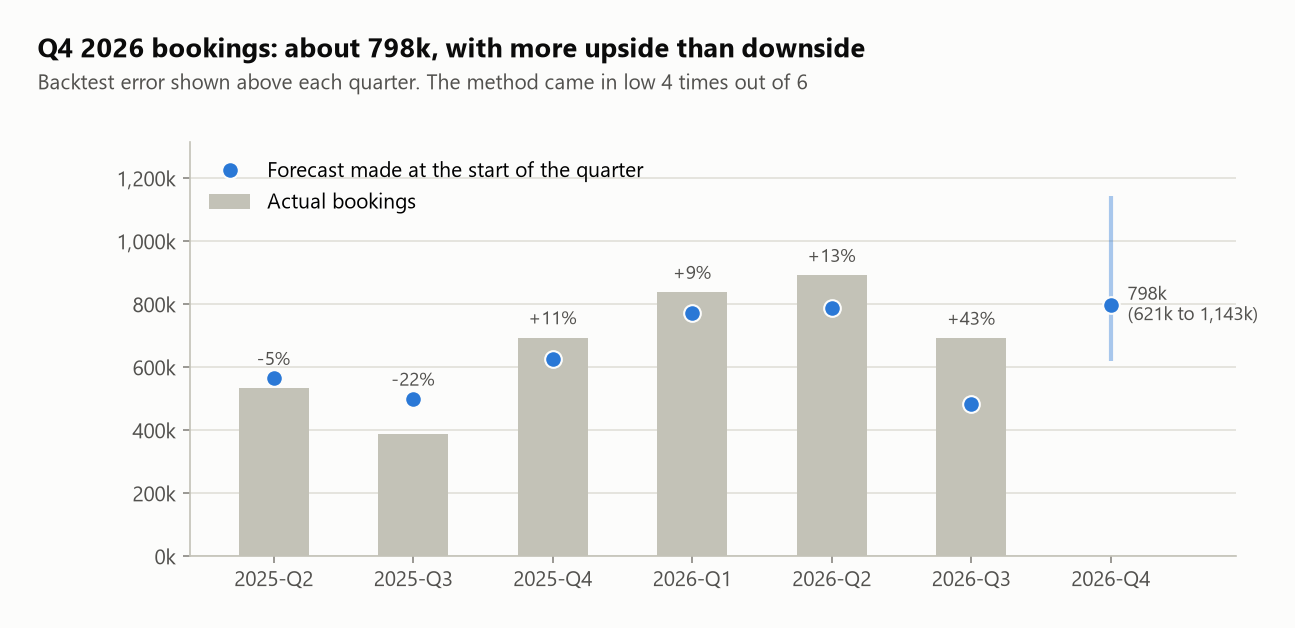

In [13]:
fc = forecast.run(r["pipeline_snapshots"], r["quarterly_bookings"], deals)
display(fc.backtest[["quarter", "open_deals", "from_open_pipeline", "run_rate_new_deals", "forecast", "actual", "error_pct"]])
n = fc.next_quarter
print(f"{n['quarter']}: {n['forecast']:,.0f}  (range {n['low']:,.0f} to {n['high']:,.0f})   "
      f"backtest mean absolute error {n['backtest_mape']:.1%}")
charts.forecast_backtest(fc.backtest, n, FIG / "13_forecast_backtest.png")
Image(FIG / "13_forecast_backtest.png")

The forecast for Q4 2026 is about 798k (417k from the open pipeline, 381k from new deals), with a range of 621k to 1.14M. Over six backtest quarters the method was off by 17% on average.

The errors are not symmetric. The method came in low in four of six quarters, and by 43% in the most recent one. That is what a method built on historical conversion rates does in a business whose conversion is improving: it is always a step behind. The point forecast implies +15% on Q4 2025, while the last three quarters grew between 65% and 78% year over year, so I would plan on the point estimate and treat the upper half of the range as the more likely miss.

I also tried estimating the stage rates on only the last two or three quarters instead of all history. Two quarters cut the backtest error to about 12% and moved the Q4 forecast to around 870k. I did not adopt it: with six backtest quarters, picking the window that scores best on those same quarters would flatter the backtest more than it would improve the forecast.

## What I would do next with real data

* Add the activity signals a CRM has and this dataset does not (meetings, emails, days since last touch). They are what usually lifts a win model above 0.65.
* Forecast at deal level for the large deals in Negotiation and keep the statistical method for the long tail.
* Re-run the backtest every quarter and watch the bias: if it keeps coming in low, move to a shorter estimation window and say so openly.